In [1]:
import numpy as np
from scipy import integrate as intg
from matplotlib import pyplot as plt 
from matplotlib import cm 
from matplotlib import colors as mclr

In [75]:
def f(v):
    return 0.5*(( 3.-np.sqrt(v) )/v**2).astype(complex)

def full_integrand(v, alpha,s):

    th = lambda v: np.tanh(np.sqrt(1.+0.j-alpha**2*f(v)**2 )*s ) 

    
    return (np.log( 1.- ( alpha*f(v) *th(v) /(np.sqrt(1.+0.j-alpha**2*f(v)**2) + th(v) ))**4 ) ).astype(complex) 

def integral(alpha,s):
    integrand = lambda v: full_integrand(v,alpha,s) 
    return intg.quad(integrand,1.,100.)[0]

def perturbative(alpha,s):
    prefactor = (0.5)**4*9881./5005.
    return -prefactor*alpha**4* (np.tanh(s)/(1.+np.tanh(s)))**4 + 0.j

In [76]:
plt.rc('font', family = 'Times New Roman')
plt.rc('font', size = 14)
plt.rc('text', usetex=True)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('axes', labelsize=18)
plt.rc('lines', linewidth=2.5)
plt.rc('figure',figsize=(9,8))

In [85]:
alphas = [0.2,0.3,0.4]
s = np.linspace(0.,6.,50)
full_integrals = [ np.vectorize(lambda x: integral(alpha,x))(s) for alpha in alphas ] 
pert_integrals = [ np.vectorize(lambda x: perturbative(alpha,x))(s) for alpha in alphas ]


/Users/jonathancurtis/opt/anaconda3/lib/python3.8/site-packages/scipy/integrate/_quadpack_py.py:575: ComplexWarning: Casting complex values to real discards the imaginary part
  return _quadpack._qagse(func,a,b,args,full_output,epsabs,epsrel,limit)


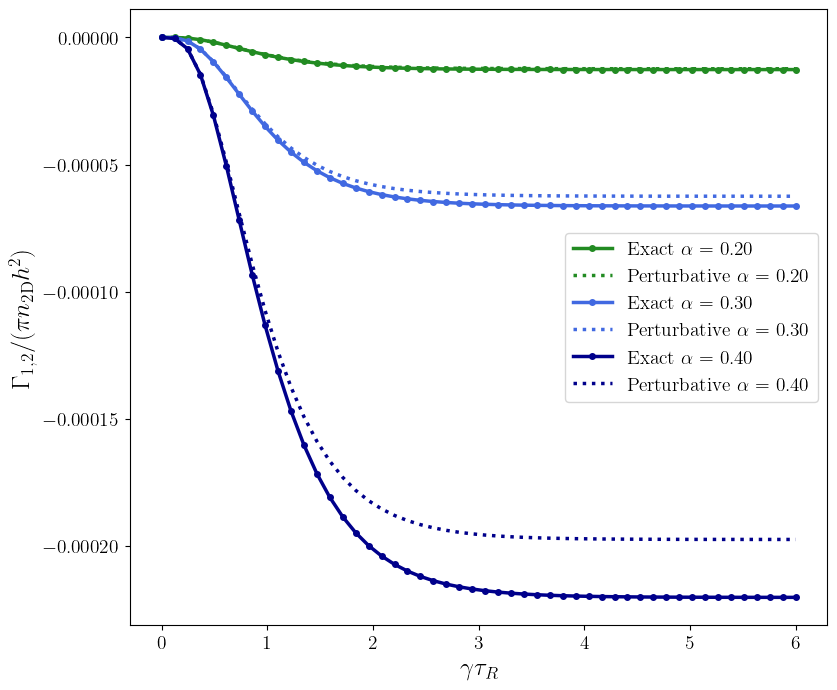

In [86]:
alpha_clrs = [mclr.CSS4_COLORS['forestgreen'], mclr.CSS4_COLORS['royalblue'],mclr.CSS4_COLORS['darkblue']]

for i in range(len(alphas)):
    plt.plot(s,full_integrals[i].real,marker='o',markersize=4.,color=alpha_clrs[i],label=r'Exact $\alpha = $'+f' {alphas[i]:0.2f}')
    plt.plot(s,pert_integrals[i].real,linestyle='dotted',color=alpha_clrs[i],label=r'Perturbative $\alpha = $'f' {alphas[i]:0.2f}')
plt.ylabel(r'$\Gamma_{1,2}/(\pi n_{\rm 2D} h^2)$')
plt.xlabel(r'$\gamma \tau_R $')
plt.legend()
plt.savefig('../figures/05292026/perturbative_comparison.pdf',bbox_inches='tight')
plt.show() 